In [16]:
import pandas as pd   # for data manipulation / handling
import matplotlib.pyplot as plt     # visualization library used for basic plots
import seaborn as sns     # visualization library used for advanced plots
from sklearn.preprocessing import LabelEncoder

In [2]:
# data loading
df=pd.read_csv(r"C:\Users\Admin\Downloads\cardekho.csv")
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0


In [6]:
# check for the null values
df.isnull().sum()

year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
seats            0
dtype: int64

In [5]:
# fill null values
df["mileage"]=df["mileage"].fillna(25)
df["engine"]=df["engine"].fillna(600)
df["seats"]=df["seats"].fillna(5)

In [8]:
# check for the duplicates
df.duplicated().sum()

np.int64(1222)

In [9]:
# drop duplicates
df.drop_duplicates(inplace=True)

In [11]:
# handling categorical columns
df["fuel"].value_counts()

fuel
Diesel    3747
Petrol    3065
CNG         56
LPG         38
Name: count, dtype: int64

In [12]:
df["encoded_fuel"]={"Diesel":0,"Petrol":1,"CNG":2,"LPG":3}


In [17]:
# handling categorical data
label=LabelEncoder()
df["encoded_fuel"]=label.fit_transform(df["fuel"])

In [18]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats,encoded_fuel
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0,1
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0,1
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0,3
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0,1
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0,3


In [19]:
df["fuel"].value_counts(),df["encoded_fuel"].value_counts()


(fuel
 Diesel    3747
 Petrol    3065
 CNG         56
 LPG         38
 Name: count, dtype: int64,
 encoded_fuel
 1    3747
 3    3065
 0      56
 2      38
 Name: count, dtype: int64)

In [20]:
# handling seller_type

label=LabelEncoder()
df["encoded_seller_type"]=label.fit_transform(df["seller_type"])

In [21]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats,encoded_fuel,encoded_seller_type
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0,1,1
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0,1,1
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0,3,1
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0,1,1
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0,3,1


In [23]:
df["seller_type"].value_counts(),df["encoded_seller_type"].value_counts()

(seller_type
 Individual          6198
 Dealer               681
 Trustmark Dealer      27
 Name: count, dtype: int64,
 encoded_seller_type
 1    6198
 0     681
 2      27
 Name: count, dtype: int64)

In [24]:
# handling transmission

label=LabelEncoder()
df["encoded_transmission"]=label.fit_transform(df["transmission"])

In [25]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0,1,1,1
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0,1,1,1
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0,3,1,1
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0,1,1,1
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0,3,1,1


In [26]:
# handling owner

label=LabelEncoder()
df["encoded_owner"]=label.fit_transform(df["owner"])

In [27]:
df.head()

,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner
0,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,5.0,1,1,1,0
1,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,5.0,1,1,1,2
2,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,5.0,3,1,1,4
3,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,5.0,1,1,1,0
4,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,5.0,3,1,1,0


In [33]:
# drop original column
df.drop(columns=["fuel","seller_type","transmission","owner"],inplace=True)

In [36]:
correlation = df.corr()
correlation

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner
year,1.000000,0.433429,-0.376281,0.275111,0.057563,0.042660,-0.068989,-0.130966,-0.141437,-0.451894
selling_price,0.433429,1.000000,-0.166033,-0.127056,0.449578,0.163558,-0.241191,-0.248647,-0.462752,-0.224338
km_driven,-0.376281,-0.166033,1.000000,-0.174932,0.223269,0.200092,-0.270658,0.109690,0.118939,0.249102
mileage,0.275111,-0.127056,-0.174932,1.000000,-0.604371,-0.463028,-0.091547,-0.004076,0.173584,-0.136853
engine,0.057563,0.449578,0.223269,-0.604371,1.000000,0.650511,-0.489921,-0.071963,-0.216568,0.001738
seats,0.042660,0.163558,0.200092,-0.463028,0.650511,1.000000,-0.342353,0.027059,0.017171,-0.002717
encoded_fuel,-0.068989,-0.241191,-0.270658,-0.091547,-0.489921,-0.342353,1.000000,0.037205,-0.028619,-0.014328
encoded_seller_type,-0.130966,-0.248647,0.109690,-0.004076,-0.071963,0.027059,0.037205,1.000000,0.181545,0.145957
encoded_transmission,-0.141437,-0.462752,0.118939,0.173584,-0.216568,0.017171,-0.028619,0.181545,1.000000,0.079744
encoded_owner,-0.451894,-0.224338,0.249102,-0.136853,0.001738,-0.002717,-0.014328,0.145957,0.079744,1.000000


<Axes: >

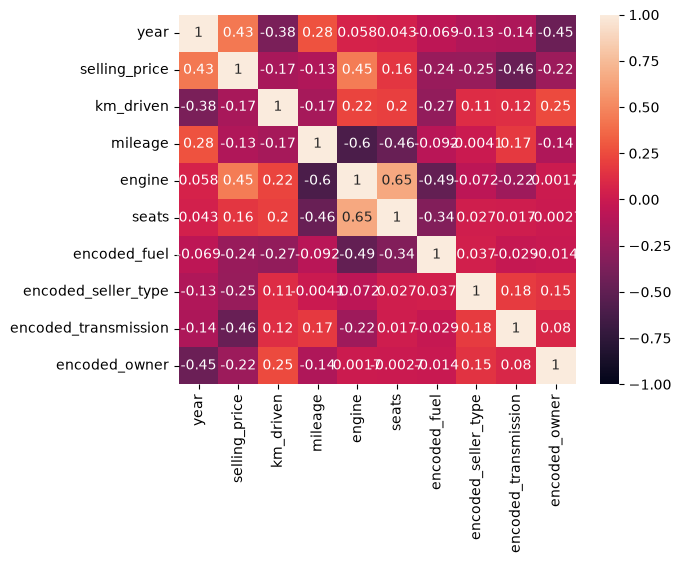

In [37]:
sns.heatmap(correlation,annot=True,vmin=-1,vmax=1,cbar=True)

In [38]:
# create a new column in which the selling price of the car by 1 lakh

df["new_selling_price"]=df["selling_price"]+100000


In [39]:
df.head()

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner,new_selling_price
0,2014,450000,145500,23.40,1248.0,5.0,1,1,1,0,550000
1,2014,370000,120000,21.14,1498.0,5.0,1,1,1,2,470000
2,2006,158000,140000,17.70,1497.0,5.0,3,1,1,4,258000
3,2010,225000,127000,23.00,1396.0,5.0,1,1,1,0,325000
4,2007,130000,120000,16.10,1298.0,5.0,3,1,1,0,230000


In [40]:
df["new_selling_price"]=df["new_selling_price"].replace(550000,568923)

In [41]:
df.head()

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner,new_selling_price
0,2014,450000,145500,23.40,1248.0,5.0,1,1,1,0,568923
1,2014,370000,120000,21.14,1498.0,5.0,1,1,1,2,470000
2,2006,158000,140000,17.70,1497.0,5.0,3,1,1,4,258000
3,2010,225000,127000,23.00,1396.0,5.0,1,1,1,0,325000
4,2007,130000,120000,16.10,1298.0,5.0,3,1,1,0,230000


In [49]:
# sort data descending wrt km_driven

df.sort_values(by="km_driven",ascending=False,ignore_index=True,inplace=True)

In [50]:
df.head()

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner,new_selling_price
0,2007,550000,2360457,18.60,1197.0,5.0,3,1,1,2,650000
1,2012,500000,1500000,15.10,2179.0,7.0,1,1,1,0,600000
2,2010,194000,577414,18.90,1061.0,5.0,3,1,1,2,294000
3,2011,229999,500000,18.90,998.0,5.0,3,1,1,2,329999
4,2011,350000,500000,12.99,2494.0,7.0,1,1,1,2,450000


In [51]:
# data copy

data = df.copy()           # deep copy

In [52]:
data.head()

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner,new_selling_price
0,2007,550000,2360457,18.60,1197.0,5.0,3,1,1,2,650000
1,2012,500000,1500000,15.10,2179.0,7.0,1,1,1,0,600000
2,2010,194000,577414,18.90,1061.0,5.0,3,1,1,2,294000
3,2011,229999,500000,18.90,998.0,5.0,3,1,1,2,329999
4,2011,350000,500000,12.99,2494.0,7.0,1,1,1,2,450000


In [53]:
data = df    # shallow copy

In [54]:
data.head()

,year,selling_price,km_driven,mileage,engine,seats,encoded_fuel,encoded_seller_type,encoded_transmission,encoded_owner,new_selling_price
0,2007,550000,2360457,18.60,1197.0,5.0,3,1,1,2,650000
1,2012,500000,1500000,15.10,2179.0,7.0,1,1,1,0,600000
2,2010,194000,577414,18.90,1061.0,5.0,3,1,1,2,294000
3,2011,229999,500000,18.90,998.0,5.0,3,1,1,2,329999
4,2011,350000,500000,12.99,2494.0,7.0,1,1,1,2,450000


In [5]:
import numpy as np
import matplotlib.pyplot as plt

In [6]:
# Dataset with 30 elements, including extreme low and high values
data = np.array([2, 5, 6, 7, 8, 9, 100, 110, 120, 130, 140, 15, 16, 500,523, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 160, 140])

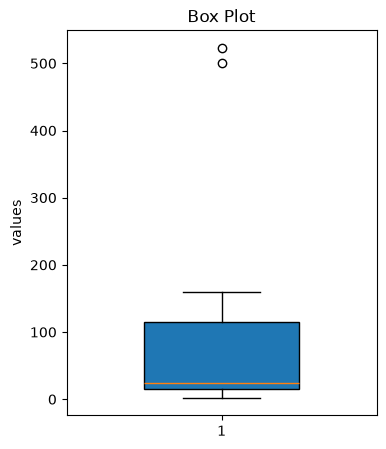

In [12]:
# box plot is used to find the outliers
# to remove outliers we use iqr

plt.figure(figsize=(4,5))
plt.boxplot(data,patch_artist=True,widths=0.5)   # patch artist fill the box with color
plt.title("Box Plot")
plt.ylabel("values")
plt.show()

In [13]:
# remove outliers
# calculate Q1 (25th percentile)
Q1 = np.percentile(data, 25)
Q1

np.float64(15.5)

In [14]:
# calculate Q3 (75th percentile)
Q3 = np.percentile(data, 75)
Q3

np.float64(115.0)

In [15]:
# calculate IQR (interquartile range)
IQR = Q3 -Q1
IQR

np.float64(99.5)

In [16]:
# calculate lower bound and upper bound
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(lower_bound)
print(upper_bound)

-133.75
264.25


In [19]:
# find indices of non-outliers (values >= lower_bound and <= upper_bound)

outliers_indices = np.where((data < lower_bound) | (data > upper_bound))
outliers = data[outliers_indices]

outliers

array([500, 523])

In [20]:
# find indices of non-outliers (values >= lower_bound and <= upper_bound)
non-outliers_indices = np.where((data >= lower_bound) & (data <= upper_bound))
data_no_outliers = data[non_outliers_indices]

data_no_outliers

SyntaxError: cannot assign to expression here. Maybe you meant '==' instead of '='? (867392366.py, line 2)

In [25]:
# load the data
import pandas as pd
import seaborn as sns

df = pd.read_csv(r"C:\Users\Admin\Downloads\employee_sales.csv")
df.head()

,employee_id,employee_name,department,region,product_category,salary,units_sold,sales_amount,hire_date
0,1,Alice Johnson,Sales,North,Electronics,75000,45,22500,15-03-2022
1,2,Bob Smith,Marketing,South,Clothing,68000,0,0,20-01-2023
2,3,Carol White,Sales,East,Electronics,72000,62,31000,10-11-2021
3,4,David Brown,HR,West,Home,55000,0,0,05-02-2024
4,5,Eva Davis,Sales,North,Clothing,78000,38,11400,12-08-2022


In [30]:
# deaprtment values count
data = df["department"].value_counts()
data

department
Sales        50
Marketing    18
HR           16
IT           16
Name: count, dtype: int64

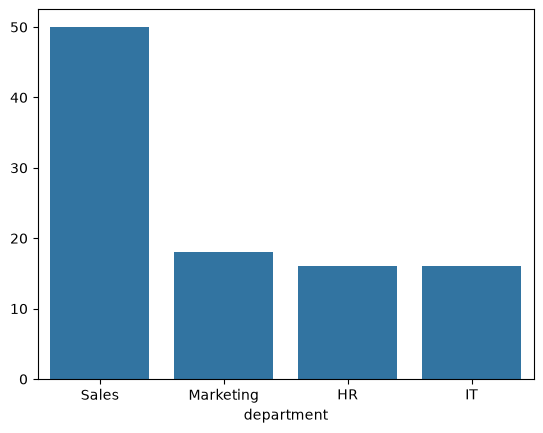

In [33]:
# count plot
sns.barplot(x = data.index,y = data.values)
plt.show()